# Forward–Backward Exponential Smoothing and Its Advantages Over Running Means

## Part I: Approximating the 11-year Sunspot Cycle

In [3]:
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
# read data from the .txt file
sunspot_year, sunspot_month, sunspot = np.loadtxt("sunspot.txt", unpack=True)

# establish a decimal year time axis
sunspot_time = sunspot_year + (sunspot_month - 1) / 12

In [9]:
# apply a 13-month running mean 
def smooth_by_running_mean(data, time):
    n = len(time)
    running_mean_13 = data.copy()

    for i in range(6, n - 6):
        mean = (data[i-6] + data[i+6]) / 24

        for j in range(i-5, i+6):
            mean += data[j] / 12

        running_mean_13[i] = mean

    return running_mean_13

sunspot_number_running_mean_smoothing = smooth_by_running_mean(sunspot, sunspot_time)

In [13]:
# apply forward-backward exponential smoothing
def forward_backward_exponential_smoothing(measurements, alpha):
    f_smoothed_points = np.zeros(measurements.size)
    b_smoothed_points = np.zeros(measurements.size)

    # run forward exponential smoothing
    f_smoothed_points[0] = measurements[0]
    for i in range(1, measurements.size):
        f_smoothed_points[i] = f_smoothed_points[i - 1] + alpha * (measurements[i] - f_smoothed_points[i-1])
    
    # run backward exponential smoothing
    b_smoothed_points[b_smoothed_points.size - 1] = f_smoothed_points[f_smoothed_points.size - 1]
    for i in range(measurements.size - 2, -1, -1):
        b_smoothed_points[i] = b_smoothed_points[i + 1] + alpha * (f_smoothed_points[i] - b_smoothed_points[i + 1])

    return b_smoothed_points

In [1]:
# find alpha values that improve both Assignment 3 smoothing indicators
def find_better_alpha(measurements, time, running_mean, alpha_values=None):
    measurements = np.asarray(measurements, dtype=float)
    time = np.asarray(time)
    running_mean = np.asarray(running_mean, dtype=float)

    if measurements.ndim != 1 or measurements.size < 3:
        raise ValueError("measurements must be a one-dimensional array with at least 3 values")
    if time.shape != measurements.shape or running_mean.shape != measurements.shape:
        raise ValueError("time and running_mean must have the same shape as measurements")
    if not (np.all(np.isfinite(measurements)) and np.all(np.isfinite(running_mean))):
        raise ValueError("measurements and running_mean must contain only finite values")

    if alpha_values is None:
        alpha_values = np.linspace(0.01, 1.0, 1000)
    else:
        alpha_values = np.asarray(alpha_values, dtype=float)
    if (alpha_values.ndim != 1 or alpha_values.size == 0
            or not np.all(np.isfinite(alpha_values))
            or np.any((alpha_values < 0) | (alpha_values > 1))):
        raise ValueError("alpha_values must be a non-empty 1D array of values between 0 and 1")

    def indicators(estimated):
        deviation = np.sum((measurements - estimated) ** 2)
        variability = np.sum((estimated[2:] - 2 * estimated[1:-1] + estimated[:-2]) ** 2)
        return deviation, variability

    baseline_deviation, baseline_variability = indicators(running_mean)
    if baseline_deviation <= 0 or baseline_variability <= 0:
        raise ValueError("running_mean indicators must be positive for normalized comparison")

    deviations = []
    variabilities = []
    candidates = []
    for alpha in alpha_values:
        estimated = forward_backward_exponential_smoothing(measurements, alpha)
        deviation, variability = indicators(estimated)
        deviations.append(deviation)
        variabilities.append(variability)
        if deviation < baseline_deviation and variability < baseline_variability:
            score = deviation / baseline_deviation + variability / baseline_variability
            candidates.append((score, alpha, deviation, variability, estimated))

    if not candidates:
        raise ValueError("No tested alpha improves both indicators over the 13-month running mean")

    # Among candidates improving both indicators, minimize their equally weighted normalized sum.
    _, best_alpha, best_deviation, best_variability, best_smoothed = min(
        candidates, key=lambda candidate: candidate[0]
    )
    print(f"13-month running mean: deviation = {baseline_deviation:.3f}, variability = {baseline_variability:.3f}")
    print(f"Selected alpha = {best_alpha:.3f}")
    print(f"Forward-backward exponential smoothing: deviation = {best_deviation:.3f}, variability = {best_variability:.3f}")
    print(f"Improvement: deviation = {(1 - best_deviation / baseline_deviation) * 100:.2f}%, "
          f"variability = {(1 - best_variability / baseline_variability) * 100:.2f}%")

    fig, axes = plt.subplots(3, 1, figsize=(12, 11))
    axes[0].plot(time, measurements, color='gray', alpha=0.5, label='Original Sunspot Data')
    axes[0].plot(time, running_mean, color='blue', label='13-Month Running Mean')
    axes[0].plot(time, best_smoothed, color='red', label=f'Forward-Backward Exponential, alpha = {best_alpha:.3f}')
    axes[0].set_ylabel('Sunspot Number')
    axes[0].legend()
    axes[0].grid()

    axes[1].plot(alpha_values, deviations, color='purple')
    axes[1].axhline(baseline_deviation, color='blue', linestyle='--', label='13-month running mean')
    axes[1].axvline(best_alpha, color='red', linestyle=':', label=f'Selected alpha = {best_alpha:.3f}')
    axes[1].set_ylabel('Deviation indicator')
    axes[1].legend()
    axes[1].grid()

    axes[2].plot(alpha_values, variabilities, color='darkgreen')
    axes[2].axhline(baseline_variability, color='blue', linestyle='--', label='13-month running mean')
    axes[2].axvline(best_alpha, color='red', linestyle=':', label=f'Selected alpha = {best_alpha:.3f}')
    axes[2].set_xlabel('Smoothing constant alpha')
    axes[2].set_ylabel('Variability indicator')
    axes[2].legend()
    axes[2].grid()
    fig.tight_layout()
    plt.show()

    return best_alpha, best_smoothed

sunspot_best_alpha, sunspot_number_fb_expo_smoothing = find_better_alpha(
    sunspot, sunspot_time, sunspot_number_running_mean_smoothing
)

NameError: name 'sunspot' is not defined

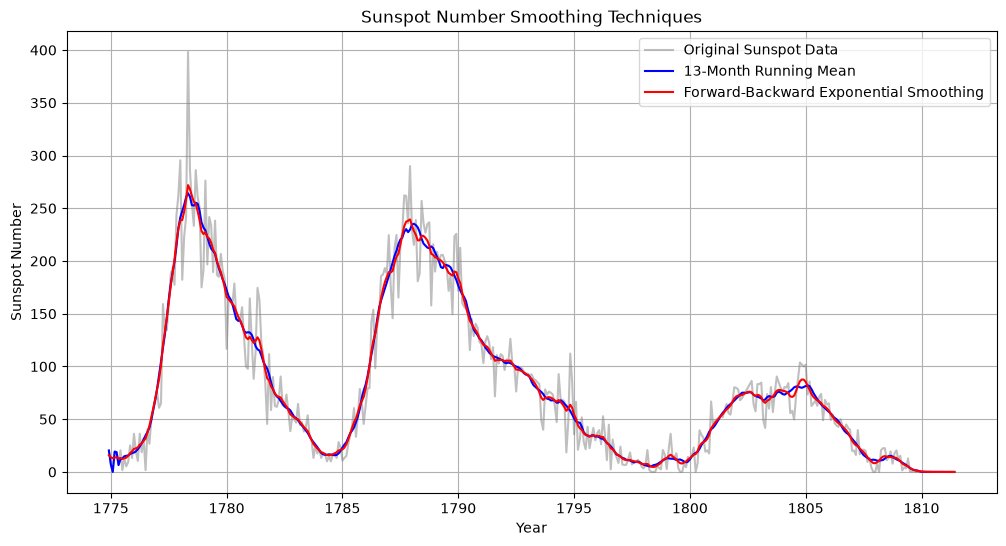

In [14]:
# plot the results of running mean smoothing and forward-backward exponential smoothing
plt.figure(figsize=(12, 6))
plt.plot(sunspot_time, sunspot, label='Original Sunspot Data', color='gray', alpha=0.5)
plt.plot(sunspot_time, sunspot_number_running_mean_smoothing, label='13-Month Running Mean', color='blue')
plt.plot(sunspot_time, sunspot_number_fb_expo_smoothing, label='Forward-Backward Exponential Smoothing', color='red')
plt.xlabel('Year')
plt.ylabel('Sunspot Number')
plt.title('Sunspot Number Smoothing Techniques')
plt.legend()
plt.grid()
plt.show()

## Part II: 3D Surface Reconstruction Under Noise

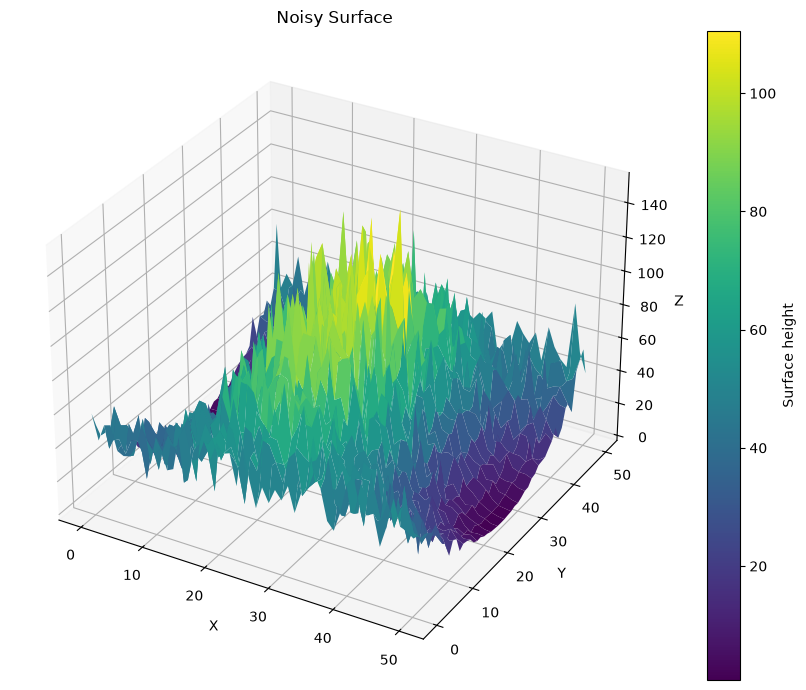

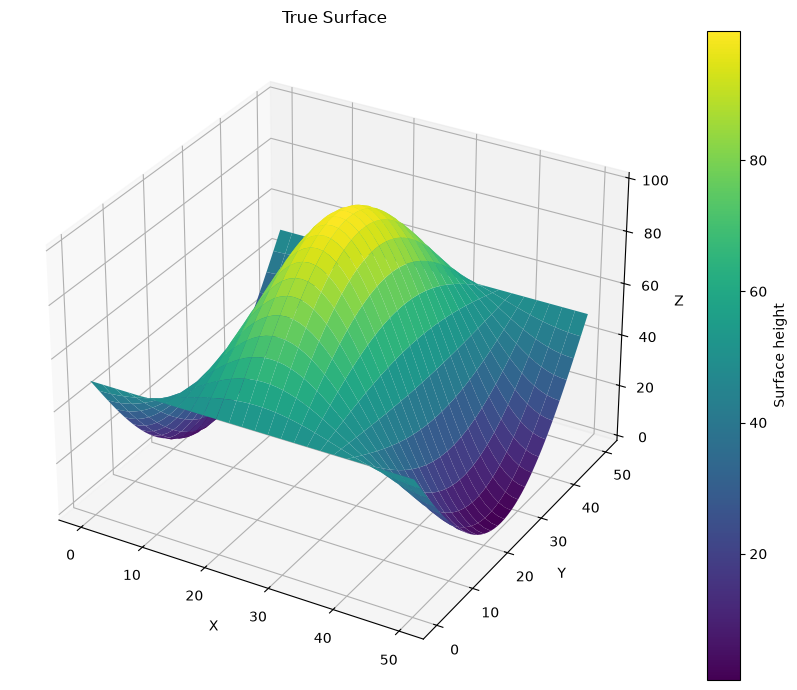

In [14]:
# load surface data from the .txt files
noisy_surface = np.loadtxt("noisy_surface.txt")
true_surface = np.loadtxt("true_surface.txt")

def plot_surface(surface, title, cmap="viridis"):
    x = np.arange(surface.shape[1])
    y = np.arange(surface.shape[0])
    X, Y = np.meshgrid(x, y)
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")
    surface_plot = ax.plot_surface(X, Y, surface, cmap=cmap)
    fig.colorbar(surface_plot, ax=ax, label="Surface height")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

plot_surface(noisy_surface, "Noisy Surface")
plot_surface(true_surface, "True Surface")

In [17]:
# flatten the matrices to 1D arrays for smoothing
noisy_surface_flat = noisy_surface.reshape(-1)
true_surface_flat = true_surface.reshape(-1)

# create an array of devations
deviations = noisy_surface_flat - true_surface_flat

# find variance of the deviations
variance = np.var(deviations)
print(f"Variance of the deviations between noisy and true surface: {variance:.6f}")


Variance of the deviations between noisy and true surface: 129.057767


In [ ]:
# apply forward-backward exponential smoothing to the noisy surface
def smooth_surface(surface, alpha):
    